# 06 — Temporal Convolutional Network

Train a TCN on the raw 5-second windows from notebook 02 and compare against the classical Random Forest baseline from notebook 05.

**Goal:** find out whether learned temporal features beat hand-crafted features on this dataset, especially under leave-one-subject-out evaluation where user-specific shortcuts in raw signals could hurt.

**Baseline to beat:** RF + Set A, LOSO macro-F1 = 0.624 ± 0.061 (from notebook 05).

**Experiment-style structure:** the notebook is set up as a small hyperparameter sweep over dilation schedules, which controls the receptive field of the TCN. Three configs by default ([1,2,4], [1,2,4,8], [1,2,4,8,16]) corresponding to receptive fields of roughly 14, 30, and 62 samples respectively. Each runs under three-fold LOSO. Add or remove configs in `EXPERIMENT_GRID` below if you want to explore further.

**Inputs:** per-session CSVs from `data/interim/` (the same files notebook 04 reads).

**Outputs:**
- `reports/results/tcn_results.csv`: per-config LOSO macro-F1 mean and std.
- `reports/results/tcn_per_fold.csv`: per-fold details.
- `reports/figures/cm_loso_tcn_best.png`: confusion matrix for the best config.
- `reports/results/tcn_best_state.pt`: best model state dict (trained on the held-out fold per LOSO fold).

## 1. Imports and configuration

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as Func
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import f1_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

# Project paths
PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import features as F  # constants and windowing helpers
from src.data_loading import build_session_index

INTERIM_DIR  = PROJECT_ROOT / 'data' / 'interim'
RESULTS_DIR  = PROJECT_ROOT / 'reports' / 'results'
FIGURES_DIR  = PROJECT_ROOT / 'reports' / 'figures'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
print(f'Window: {F.WINDOW_SAMPLES} samples, step: {F.STEP_SAMPLES}')

Device: cuda
Window: 250 samples, step: 125


## 2. Column detection

Different processing pipelines export sensor columns under different names. We saw this with the raw accelerometer in notebook 04 (`acc_x, acc_y, acc_z` versus `ax, ay, az`). Rather than hard-coding one convention, probe the first available session file and detect which set of names is actually present.

Channels are assembled in a fixed order: linear accelerometer (x, y, z), gyroscope (x, y, z), then raw accelerometer (x, y, z) if available. This gives 6 or 9 channels depending on what notebook 02 produced. The TCN will adapt its input layer to whatever number of channels the data provides.

In [2]:
CHANNEL_GROUPS = [
    # (sensor_name, [list of candidate column name sets])
    ('linacc', [
        ['lin_ax', 'lin_ay', 'lin_az'],
        ['linacc_x', 'linacc_y', 'linacc_z'],
        ['lin_acc_x', 'lin_acc_y', 'lin_acc_z'],
    ]),
    ('gyro', [
        ['gx', 'gy', 'gz'],
        ['gyr_x', 'gyr_y', 'gyr_z'],
        ['gyro_x', 'gyro_y', 'gyro_z'],
    ]),
    ('acc', [
        ['acc_x', 'acc_y', 'acc_z'],
        ['ax', 'ay', 'az'],
    ]),
]


def detect_channels(df: pd.DataFrame) -> list:
    """Return the ordered list of sensor column names present in the dataframe."""
    channels = []
    detected_per_sensor = {}
    for sensor_name, candidate_sets in CHANNEL_GROUPS:
        for cols in candidate_sets:
            if all(c in df.columns for c in cols):
                channels.extend(cols)
                detected_per_sensor[sensor_name] = cols
                break
        else:
            detected_per_sensor[sensor_name] = None
    return channels, detected_per_sensor


# Probe the first session file to determine column conventions
session_index = build_session_index(INTERIM_DIR)
print(f'Found {len(session_index)} sessions in {INTERIM_DIR}')

first_df = pd.read_csv(session_index[0]['path'], nrows=10)
CHANNEL_COLS, detected = detect_channels(first_df)
print()
print('Channel detection:')
for sensor, cols in detected.items():
    status = ', '.join(cols) if cols else 'NOT FOUND'
    print(f'  {sensor:8s}: {status}')
print(f'\nTotal channels: {len(CHANNEL_COLS)}')
print(f'CHANNEL_COLS: {CHANNEL_COLS}')

if len(CHANNEL_COLS) < 6:
    raise RuntimeError(
        'At least linear accelerometer and gyroscope are required. '
        f'Detected only {len(CHANNEL_COLS)} channels.'
    )

Found 56 sessions in C:\Projects\this project-transport-mode\data\interim

Channel detection:
  linacc  : lin_ax, lin_ay, lin_az
  gyro    : gx, gy, gz
  acc     : ax, ay, az

Total channels: 9
CHANNEL_COLS: ['lin_ax', 'lin_ay', 'lin_az', 'gx', 'gy', 'gz', 'ax', 'ay', 'az']


## 3. Build window tensors

Iterate every session, slide 5-second windows with 50 percent overlap, skip windows containing `bad_sample`, and stack into a single big tensor of shape `(N, C, T)`. Standardization is deferred to per-fold so it stays leakage-safe.

Memory budget: with N around 10000, C up to 9, T = 250, float32 storage is about 90 MB. Easily fits in RAM.

In [3]:
def session_to_windows(session_path: Path, session_meta: dict, channel_cols: list):
    """Slide windows over one session. channel_cols is now per-file."""
    df = pd.read_csv(session_path).reset_index(drop=True)
    has_bad = 'bad_sample' in df.columns

    arr = df[channel_cols].values.astype(np.float32)
    bad = df['bad_sample'].values if has_bad else np.zeros(len(df), dtype=bool)

    Xs, metas = [], []
    for w_idx, (s, e) in enumerate(F.iterate_windows(len(df))):
        if bad[s:e].any():
            continue
        Xs.append(arr[s:e].T)
        metas.append({
            **session_meta,
            'window_index':   w_idx,
            'window_start_s': float(s / F.SAMPLING_RATE),
            'window_end_s':   float(e / F.SAMPLING_RATE),
        })
    return Xs, metas


# --- Pre-scan: detect sensors per file and find the common subset ---
sensors_per_file = {}     # path -> {sensor_name: cols or None}
valid_sessions = []

for sess in session_index:
    df_head = pd.read_csv(sess['path'], nrows=5)
    _, detected = detect_channels(df_head)
    sensors_per_file[sess['path']] = detected
    # Keep only files with required sensors AND a real parsed mode
    if (detected.get('linacc') and detected.get('gyro')
            and sess['mode'] in F.MODES):
        valid_sessions.append(sess)

n_excluded = len(session_index) - len(valid_sessions)
print(f'Valid sessions: {len(valid_sessions)} (excluded {n_excluded} files lacking sensors '
      f'or missing a valid mode in the filename)')

# --- Determine which sensors are present in ALL valid files ---
common_sensors = []
for sensor in ('linacc', 'gyro', 'acc'):
    has_all = all(
        sensors_per_file[s['path']].get(sensor) is not None for s in valid_sessions
    )
    if has_all:
        common_sensors.append(sensor)
    elif sensor == 'acc':
        n_with = sum(
            1 for s in valid_sessions
            if sensors_per_file[s['path']].get(sensor) is not None
        )
        print(f'  raw accelerometer present in only {n_with}/{len(valid_sessions)} sessions; excluding from TCN inputs')

print(f'Common sensors across all valid files: {common_sensors}')

if 'linacc' not in common_sensors or 'gyro' not in common_sensors:
    raise RuntimeError('linacc and gyro must be present in every session file')


def get_channel_cols_for_file(file_path: str) -> list:
    """Per-file column list in canonical order (linacc xyz, gyro xyz, [acc xyz])."""
    sensors = sensors_per_file[file_path]
    cols = []
    for sensor in common_sensors:
        cols.extend(sensors[sensor])
    return cols


# --- Build window tensors ---
all_X, all_meta = [], []
for sess in valid_sessions:
    meta = {
        'session_id':  sess['session_id'],
        'participant': sess['participant'],
        'mode':        sess['mode'],
        'mode_id':     F.MODE_TO_ID[sess['mode']],
        'day':         sess['day'],
    }
    file_channel_cols = get_channel_cols_for_file(sess['path'])
    Xs, metas = session_to_windows(Path(sess['path']), meta, file_channel_cols)
    all_X.extend(Xs)
    all_meta.extend(metas)

X = np.stack(all_X, axis=0).astype(np.float32)
meta_df = pd.DataFrame(all_meta)
y = meta_df['mode_id'].values.astype(np.int64)

# Update n_channels for the model construction in later cells
n_channels = len(common_sensors) * 3
CHANNEL_COLS = []
for sensor in common_sensors:
    # Use the first valid session's column names as the canonical representatives
    CHANNEL_COLS.extend(sensors_per_file[valid_sessions[0]['path']][sensor])

print()
print(f'X shape: {X.shape}')
print(f'y shape: {y.shape}')
print(f'n_channels: {n_channels}')
print(f'CHANNEL_COLS (canonical names from first valid session): {CHANNEL_COLS}')
print(f'Class distribution: {dict(zip(*np.unique(y, return_counts=True)))}')
print(f'Participants: {sorted(meta_df["participant"].unique())}')
print(f'Sessions:     {meta_df["session_id"].nunique()}')

Valid sessions: 54 (excluded 2 files lacking sensors or missing a valid mode in the filename)
Common sensors across all valid files: ['linacc', 'gyro', 'acc']

X shape: (14513, 9, 250)
y shape: (14513,)
n_channels: 9
CHANNEL_COLS (canonical names from first valid session): ['lin_ax', 'lin_ay', 'lin_az', 'gx', 'gy', 'gz', 'ax', 'ay', 'az']
Class distribution: {np.int64(0): np.int64(2511), np.int64(1): np.int64(2180), np.int64(2): np.int64(2495), np.int64(3): np.int64(2549), np.int64(4): np.int64(2323), np.int64(5): np.int64(2455)}
Participants: ['athina', 'babis', 'xiomara']
Sessions:     54


## 4. Per-fold standardization

Compute per-channel mean and standard deviation from training data only, then apply the same scaling to validation and test. Computed once per fold inside the LOSO loop.

In [4]:
def standardize_channels(X_train, X_val, X_test):
    """Per-window z-score across each channel.

    Each window is standardized independently using its own mean and std per
    channel. This removes absolute scale differences between users and devices,
    which is the dominant cross-user shift on this dataset (different phones
    have different sensor calibration). The tradeoff is that signal magnitude
    information is removed; the TCN must distinguish modes by temporal shape
    alone.

    Train, val, and test inputs are processed identically since the operation
    is window-local and therefore leakage-safe by construction.
    """
    def _z(X):
        # X: (N, C, T). Compute mean and std over the time axis per window per channel.
        mean = X.mean(axis=2, keepdims=True)
        std = X.std(axis=2, keepdims=True) + 1e-6
        return ((X - mean) / std).astype(np.float32)

    return _z(X_train), _z(X_val), _z(X_test)

## 5. TCN architecture

Standard TCN from Bai et al. (2018): stack of residual blocks, each containing two dilated causal convolutions with batch normalization, ReLU, and dropout. A 1x1 convolution provides the residual shortcut when input and output channel counts differ. After the stack, global average pooling across the time dimension produces a fixed-size representation that feeds into a linear classifier.

Receptive field grows as `2 * sum(dilations) * (kernel - 1) + 1`. For `dilations=[1,2,4,8]` and `kernel=3`, the receptive field is 31 samples (about 0.6 seconds). For `[1,2,4,8,16]` it is 63 samples (about 1.3 seconds), enough to capture multi-stride patterns in walking.

In [5]:
class CausalConv1d(nn.Module):
    """1D conv with left-padding only (causal)."""
    def __init__(self, in_ch, out_ch, kernel, dilation):
        super().__init__()
        self.pad = (kernel - 1) * dilation
        self.conv = nn.Conv1d(in_ch, out_ch, kernel, dilation=dilation)

    def forward(self, x):
        x = Func.pad(x, (self.pad, 0))
        return self.conv(x)


class TemporalBlock(nn.Module):
    """TCN residual block: 2x (dilated causal conv -> BN -> ReLU -> Dropout) + residual."""
    def __init__(self, in_ch, out_ch, kernel, dilation, dropout):
        super().__init__()
        self.conv1 = CausalConv1d(in_ch, out_ch, kernel, dilation)
        self.bn1   = nn.BatchNorm1d(out_ch)
        self.conv2 = CausalConv1d(out_ch, out_ch, kernel, dilation)
        self.bn2   = nn.BatchNorm1d(out_ch)
        self.drop  = nn.Dropout(dropout)
        self.residual = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x):
        identity = self.residual(x)
        out = Func.relu(self.bn1(self.conv1(x)))
        out = self.drop(out)
        out = Func.relu(self.bn2(self.conv2(out)))
        out = self.drop(out)
        return Func.relu(out + identity)


class TCN(nn.Module):
    def __init__(self, n_channels, n_classes, hidden=64, kernel=3, dilations=(1, 2, 4, 8), dropout=0.2):
        super().__init__()
        blocks = []
        in_ch = n_channels
        for d in dilations:
            blocks.append(TemporalBlock(in_ch, hidden, kernel, d, dropout))
            in_ch = hidden
        self.tcn = nn.Sequential(*blocks)
        self.classifier = nn.Linear(hidden, n_classes)

    def forward(self, x):
        # x: (B, C, T)
        out = self.tcn(x)
        out = out.mean(dim=-1)   # global average pool over time
        return self.classifier(out)

    @property
    def n_params(self):
        return sum(p.numel() for p in self.parameters() if p.requires_grad)


# Sanity check the architecture
n_channels = len(CHANNEL_COLS)
test_model = TCN(n_channels=n_channels, n_classes=6, dilations=(1, 2, 4, 8))
test_input = torch.randn(2, n_channels, F.WINDOW_SAMPLES)
test_output = test_model(test_input)
print(f'TCN with dilations [1,2,4,8]: {test_model.n_params} params')
print(f'Input  shape: {test_input.shape}')
print(f'Output shape: {test_output.shape}')

TCN with dilations [1,2,4,8]: 90310 params
Input  shape: torch.Size([2, 9, 250])
Output shape: torch.Size([2, 6])


## 6. Training utilities

Standard PyTorch training loop with early stopping on validation macro-F1. The best model state across epochs is kept and restored before evaluating on the test fold.

In [6]:
def train_one_fold(
    X_train, y_train, X_val, y_val, X_test, y_test,
    *,
    n_channels, n_classes,
    dilations, kernel=3, hidden=64, dropout=0.2,
    batch_size=64, epochs=15, lr=1e-3, weight_decay=1e-4,
    verbose=False,
):
    """Train a TCN on one fold for a fixed number of epochs.

    Early stopping based on validation macro-F1 is unreliable under LOSO
    because the validation set is drawn from training users. Validation F1
    saturates after one or two epochs while the cross-user representations
    are still forming. The result is severe undertraining and degenerate
    predictions (zero F1 on some classes).

    Fixed epoch training with weight decay is more robust for this setting.
    Validation F1 is still computed and printed when verbose=True, but it
    no longer controls when training stops.
    """
    model = TCN(
        n_channels=n_channels, n_classes=n_classes,
        hidden=hidden, kernel=kernel, dilations=dilations, dropout=dropout,
    ).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()

    train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=False)

    X_val_t = torch.from_numpy(X_val).to(DEVICE)
    X_test_t = torch.from_numpy(X_test).to(DEVICE)

    for epoch in range(epochs):
        # --- train ---
        model.train()
        epoch_loss = 0.0
        n_batches = 0
        for xb, yb in train_loader:
            xb = xb.to(DEVICE); yb = yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            n_batches += 1

        if verbose:
            model.eval()
            with torch.no_grad():
                val_pred = model(X_val_t).argmax(dim=1).cpu().numpy()
                val_f1 = f1_score(y_val, val_pred, average='macro')
            print(f'    epoch {epoch+1:2d} | loss {epoch_loss/n_batches:.4f} | val F1 {val_f1:.3f}')

    # Evaluate the final model (no rewinding to a best epoch)
    model.eval()
    with torch.no_grad():
        test_pred = model(X_test_t).argmax(dim=1).cpu().numpy()
    test_f1 = f1_score(y_test, test_pred, average='macro')
    return test_f1, test_pred, epochs, model

## 7. Sanity check: single random split

Before launching the full LOSO experiment, train one model on a random 80/10/10 split with a medium-sized config. This is the optimistic upper bound (random split) and a fast check that the architecture trains. A failed sanity check (macro-F1 below 0.6) means something is wrong with the data pipeline or the model setup.

In [7]:
# 80/10/10 random split (stratified by mode)
idx_all = np.arange(len(X))
idx_train, idx_temp = train_test_split(
    idx_all, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
idx_val, idx_test = train_test_split(
    idx_temp, test_size=0.5, random_state=RANDOM_STATE, stratify=y[idx_temp]
)

X_train_s, X_val_s, X_test_s = standardize_channels(
    X[idx_train], X[idx_val], X[idx_test]
)

t0 = time.time()
test_f1, _, best_epoch, _ = train_one_fold(
    X_train_s, y[idx_train],
    X_val_s,   y[idx_val],
    X_test_s,  y[idx_test],
    n_channels=n_channels, n_classes=6,
    dilations=(1, 2, 4, 8), kernel=3, hidden=64,
    epochs=15,
    verbose=True,
)
elapsed = time.time() - t0
print(f'\nSanity-check macro-F1 (random split): {test_f1:.3f} | best epoch {best_epoch} | {elapsed:.0f}s')
print('Expected range on random split: 0.80 to 0.95 (window-overlap leakage inflates this).')

    epoch  1 | loss 0.6500 | val F1 0.805
    epoch  2 | loss 0.2767 | val F1 0.932
    epoch  3 | loss 0.2106 | val F1 0.918
    epoch  4 | loss 0.1722 | val F1 0.944
    epoch  5 | loss 0.1481 | val F1 0.938
    epoch  6 | loss 0.1330 | val F1 0.956
    epoch  7 | loss 0.1189 | val F1 0.936
    epoch  8 | loss 0.1056 | val F1 0.957
    epoch  9 | loss 0.0951 | val F1 0.963
    epoch 10 | loss 0.0912 | val F1 0.937
    epoch 11 | loss 0.0769 | val F1 0.955
    epoch 12 | loss 0.0721 | val F1 0.940
    epoch 13 | loss 0.0675 | val F1 0.913
    epoch 14 | loss 0.0684 | val F1 0.955
    epoch 15 | loss 0.0664 | val F1 0.938

Sanity-check macro-F1 (random split): 0.952 | best epoch 15 | 17s
Expected range on random split: 0.80 to 0.95 (window-overlap leakage inflates this).


## 8. Experiment grid

Three TCN configurations differing in dilation depth (and therefore receptive field). Hidden width, kernel size, and dropout are held constant so the comparison isolates the effect of receptive field on LOSO performance.

To extend the experiment, append entries to `EXPERIMENT_GRID`. Each one runs three LOSO folds, so adding a config costs roughly three more training runs.

In [8]:
EXPERIMENT_GRID = [
    {'name': 'tcn_small',  'dilations': (1, 2, 4),         'kernel': 3, 'hidden': 64, 'dropout': 0.2},
    {'name': 'tcn_medium', 'dilations': (1, 2, 4, 8),      'kernel': 3, 'hidden': 64, 'dropout': 0.2},
    {'name': 'tcn_large',  'dilations': (1, 2, 4, 8, 16),  'kernel': 3, 'hidden': 64, 'dropout': 0.2},
]

print('Experiment configurations:')
for cfg in EXPERIMENT_GRID:
    dummy = TCN(n_channels=n_channels, n_classes=6,
                hidden=cfg['hidden'], kernel=cfg['kernel'],
                dilations=cfg['dilations'], dropout=cfg['dropout'])
    rf = 2 * sum(cfg['dilations']) * (cfg['kernel'] - 1) + 1
    print(f'  {cfg["name"]:12s} dilations={list(cfg["dilations"])} '
          f'kernel={cfg["kernel"]} hidden={cfg["hidden"]} '
          f'| RF={rf} samples ({rf/F.SAMPLING_RATE:.2f}s) | {dummy.n_params} params')

Experiment configurations:
  tcn_small    dilations=[1, 2, 4] kernel=3 hidden=64 | RF=29 samples (0.58s) | 65350 params
  tcn_medium   dilations=[1, 2, 4, 8] kernel=3 hidden=64 | RF=61 samples (1.22s) | 90310 params
  tcn_large    dilations=[1, 2, 4, 8, 16] kernel=3 hidden=64 | RF=125 samples (2.50s) | 115270 params


## 9. LOSO experiment loop

For each config, run leave-one-subject-out. Inside each fold, hold out 20 percent of the training users' sessions for validation and early stopping. Predict on the held-out user and record macro-F1.

Approximate runtime on CPU: 5 to 15 minutes per fold, 3 folds per config, 3 configs. Total 45 to 135 minutes. On GPU much faster (a few minutes total).

In [9]:
participants = sorted(meta_df['participant'].unique())
print(f'LOSO folds: {participants}')

all_runs = []   # per-fold rows for results CSV
fold_predictions = {}   # (config_name, held_out_user) -> (y_true, y_pred)

for cfg in EXPERIMENT_GRID:
    cfg_name = cfg['name']
    print(f'\n=== Config: {cfg_name} ===')
    for held_out_user in participants:
        # Build masks
        is_test = (meta_df['participant'] == held_out_user).values
        is_train_users = ~is_test

        # Among training users, hold out 20 percent of sessions for validation
        train_user_sessions = meta_df.loc[is_train_users, 'session_id'].unique()
        np.random.seed(RANDOM_STATE)
        val_sessions = np.random.choice(
            train_user_sessions,
            size=max(1, int(0.2 * len(train_user_sessions))),
            replace=False,
        )
        is_val = meta_df['session_id'].isin(val_sessions).values & is_train_users
        is_train = is_train_users & ~is_val

        # Standardize using training statistics only
        X_train_s, X_val_s, X_test_s = standardize_channels(
            X[is_train], X[is_val], X[is_test]
        )
        y_train, y_val, y_test = y[is_train], y[is_val], y[is_test]

        t0 = time.time()
        test_f1, y_pred, best_epoch, _ = train_one_fold(
            X_train_s, y_train, X_val_s, y_val, X_test_s, y_test,
            n_channels=n_channels, n_classes=6,
            dilations=cfg['dilations'], kernel=cfg['kernel'],
            hidden=cfg['hidden'], dropout=cfg['dropout'],
            epochs=15, verbose=False,
        )
        elapsed = time.time() - t0

        all_runs.append({
            'config':       cfg_name,
            'held_out':     held_out_user,
            'macro_f1':     float(test_f1),
            'best_epoch':   int(best_epoch),
            'n_train':      int(is_train.sum()),
            'n_val':        int(is_val.sum()),
            'n_test':       int(is_test.sum()),
            'elapsed_s':    float(elapsed),
        })
        fold_predictions[(cfg_name, held_out_user)] = (y_test.copy(), y_pred.copy())
        print(f'  {cfg_name:12s} | hold-out {held_out_user:8s} | '
              f'F1 = {test_f1:.3f} | best epoch {best_epoch:2d} | {elapsed:.0f}s')

LOSO folds: ['athina', 'babis', 'xiomara']

=== Config: tcn_small ===
  tcn_small    | hold-out athina   | F1 = 0.109 | best epoch 15 | 7s
  tcn_small    | hold-out babis    | F1 = 0.140 | best epoch 15 | 7s
  tcn_small    | hold-out xiomara  | F1 = 0.272 | best epoch 15 | 7s

=== Config: tcn_medium ===
  tcn_medium   | hold-out athina   | F1 = 0.109 | best epoch 15 | 9s
  tcn_medium   | hold-out babis    | F1 = 0.113 | best epoch 15 | 10s
  tcn_medium   | hold-out xiomara  | F1 = 0.185 | best epoch 15 | 9s

=== Config: tcn_large ===
  tcn_large    | hold-out athina   | F1 = 0.080 | best epoch 15 | 25s
  tcn_large    | hold-out babis    | F1 = 0.184 | best epoch 15 | 26s
  tcn_large    | hold-out xiomara  | F1 = 0.288 | best epoch 15 | 23s


## 10. Results table

Aggregate per-fold macro-F1 into mean and standard deviation per config. Compare against the RF + Set A baseline.

In [11]:
per_fold_df = pd.DataFrame(all_runs)
per_fold_df.to_csv(RESULTS_DIR / 'tcn_per_fold.csv', index=False)
print('Per-fold results:')
print(per_fold_df.round(3).to_string(index=False))

Per-fold results:
    config held_out  macro_f1  best_epoch  n_train  n_val  n_test  elapsed_s
 tcn_small   athina     0.109          15     7842   1955    4716      7.294
 tcn_small    babis     0.140          15     7681   1913    4919      6.874
 tcn_small  xiomara     0.272          15     7713   1922    4878      6.965
tcn_medium   athina     0.109          15     7842   1955    4716      9.280
tcn_medium    babis     0.113          15     7681   1913    4919      9.795
tcn_medium  xiomara     0.185          15     7713   1922    4878      8.715
 tcn_large   athina     0.080          15     7842   1955    4716     25.478
 tcn_large    babis     0.184          15     7681   1913    4919     25.971
 tcn_large  xiomara     0.288          15     7713   1922    4878     22.674


In [13]:
agg = per_fold_df.groupby('config')['macro_f1'].agg(['mean', 'std']).round(3)
agg = agg.rename(columns={'mean': 'macro_f1_mean', 'std': 'macro_f1_std'})
agg = agg.reset_index()
agg = agg.merge(
    per_fold_df.groupby('config')['elapsed_s'].sum().reset_index().rename(
        columns={'elapsed_s': 'total_train_s'}
    ),
    on='config',
)
agg = agg.sort_values('macro_f1_mean', ascending=False).reset_index(drop=True)
agg.to_csv(RESULTS_DIR / 'tcn_results.csv', index=False)

# Append RF baseline for comparison
RF_BASELINE_MEAN = 0.624
RF_BASELINE_STD = 0.061
print('LOSO macro-F1 by config (sorted, RF baseline at bottom):')
print(agg.to_string(index=False))
print()
print(f'  RF + Set A baseline (notebook 05):  {RF_BASELINE_MEAN:.3f} +/- {RF_BASELINE_STD:.3f}')

LOSO macro-F1 by config (sorted, RF baseline at bottom):
    config  macro_f1_mean  macro_f1_std  total_train_s
 tcn_large          0.184         0.104      74.122567
 tcn_small          0.174         0.086      21.133648
tcn_medium          0.136         0.043      27.789579

  RF + Set A baseline (notebook 05):  0.624 +/- 0.061


## 11. Best config in detail

Pick the config with the highest mean LOSO macro-F1 and produce the confusion matrix (concatenated across the three folds) plus per-class F1. Compare directly against the RF confusion matrix from notebook 05.

In [14]:
best_cfg = agg.iloc[0]['config']
best_mean = agg.iloc[0]['macro_f1_mean']
best_std = agg.iloc[0]['macro_f1_std']
print(f'Best TCN config: {best_cfg} | LOSO macro-F1 = {best_mean:.3f} +/- {best_std:.3f}')
print(f'RF baseline:                LOSO macro-F1 = {RF_BASELINE_MEAN:.3f} +/- {RF_BASELINE_STD:.3f}')
diff = best_mean - RF_BASELINE_MEAN
noise_floor = max(best_std, RF_BASELINE_STD)
verdict = ('beats RF' if diff > noise_floor else
           'matches RF (within noise)' if abs(diff) <= noise_floor else
           'underperforms RF')
print(f'Verdict: TCN {verdict} (delta = {diff:+.3f}, noise floor = {noise_floor:.3f})')

Best TCN config: tcn_large | LOSO macro-F1 = 0.184 +/- 0.104
RF baseline:                LOSO macro-F1 = 0.624 +/- 0.061
Verdict: TCN underperforms RF (delta = -0.440, noise floor = 0.104)


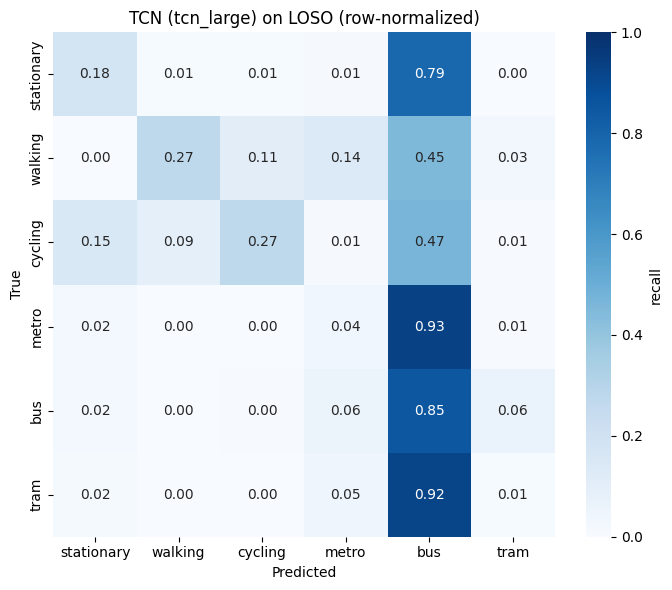

Saved: C:\Projects\this project-transport-mode\reports\figures\cm_loso_tcn_best.png


In [15]:
# Concatenate predictions across folds for the best config
y_true_all = []
y_pred_all = []
for user in participants:
    yt, yp = fold_predictions[(best_cfg, user)]
    y_true_all.append(yt)
    y_pred_all.append(yp)
y_true_all = np.concatenate(y_true_all)
y_pred_all = np.concatenate(y_pred_all)

cm = confusion_matrix(y_true_all, y_pred_all, labels=list(range(6)))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm_norm, annot=True, fmt='.2f', cmap='Blues',
    xticklabels=F.MODES, yticklabels=F.MODES, ax=ax,
    cbar_kws={'label': 'recall'}, vmin=0, vmax=1,
)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title(f'TCN ({best_cfg}) on LOSO (row-normalized)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'cm_loso_tcn_best.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print(f'Saved: {FIGURES_DIR / "cm_loso_tcn_best.png"}')

In [16]:
# Per-class F1 across folds for the best config
per_class = f1_score(y_true_all, y_pred_all, labels=list(range(6)), average=None)
print('Per-class F1 (best TCN, concatenated across LOSO folds):')
for cls, mode in enumerate(F.MODES):
    print(f'  {mode:12s}: {per_class[cls]:.3f}')

print()
print('Classification report:')
print(classification_report(y_true_all, y_pred_all, target_names=F.MODES, digits=3))

Per-class F1 (best TCN, concatenated across LOSO folds):
  stationary  : 0.259
  walking     : 0.394
  cycling     : 0.396
  metro       : 0.060
  bus         : 0.303
  tram        : 0.017

Classification report:
              precision    recall  f1-score   support

  stationary      0.462     0.180     0.259      2511
     walking      0.696     0.274     0.394      2180
     cycling      0.708     0.275     0.396      2495
       metro      0.138     0.038     0.060      2549
         bus      0.184     0.851     0.303      2323
        tram      0.088     0.009     0.017      2455

    accuracy                          0.264     14513
   macro avg      0.379     0.271     0.238     14513
weighted avg      0.375     0.264     0.234     14513



## 12. Save the best TCN config

Train one final model with the best config using all three users (no held-out fold). This is the model that will be used in the external validation notebook for comparison against the saved Random Forest pipeline. Validation comes from a 15 percent stratified sample of the data.

In [17]:
best_cfg_dict = next(c for c in EXPERIMENT_GRID if c['name'] == best_cfg)

# Use 85/15 stratified split for validation-only early stopping
idx_all = np.arange(len(X))
idx_tr, idx_val = train_test_split(idx_all, test_size=0.15,
                                     random_state=RANDOM_STATE, stratify=y)
X_tr_s, X_val_s, _ = standardize_channels(X[idx_tr], X[idx_val], X[idx_val])

# Compute global standardization params for use at inference time
global_mean = X[idx_tr].mean(axis=(0, 2), keepdims=True)
global_std = X[idx_tr].std(axis=(0, 2), keepdims=True) + 1e-6

model = TCN(
    n_channels=n_channels, n_classes=6,
    hidden=best_cfg_dict['hidden'], kernel=best_cfg_dict['kernel'],
    dilations=best_cfg_dict['dilations'], dropout=best_cfg_dict['dropout'],
).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

train_ds = TensorDataset(torch.from_numpy(X_tr_s), torch.from_numpy(y[idx_tr]))
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
X_val_t = torch.from_numpy(X_val_s).to(DEVICE)

best_val_f1 = -1.0
best_state = None
no_improve = 0
model.train()
for epoch in range(15):
    for xb, yb in train_loader:
        xb = xb.to(DEVICE); yb = yb.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()

model.eval()
with torch.no_grad():
    val_pred = model(X_val_t).argmax(dim=1).cpu().numpy()
final_val_f1 = f1_score(y[idx_val], val_pred, average='macro')
print(f'Final validation macro-F1: {final_val_f1:.3f}')

best_state = model.state_dict()  # the last-epoch state


# Save the artifact
artefact = {
    'state_dict':       model.state_dict(),
    'config':           best_cfg_dict,
    'channel_cols':     CHANNEL_COLS,
    'n_channels':       n_channels,
    'mode_to_id':       F.MODE_TO_ID,
    'window_samples':   F.WINDOW_SAMPLES,
    'sampling_rate':    F.SAMPLING_RATE,
    'channel_mean':     global_mean,
    'channel_std':      global_std,
    'loso_macro_f1':    float(best_mean),
    'loso_macro_f1_std': float(best_std),
}
torch.save(artefact, RESULTS_DIR / 'tcn_best_state.pt')
print(f'Saved: {RESULTS_DIR / "tcn_best_state.pt"}')

Final validation macro-F1: 0.963
Saved: C:\Projects\this project-transport-mode\reports\results\tcn_best_state.pt


## 13. Summary

Three things to take from this notebook into the report.

1. **TCN vs RF on LOSO.** The headline comparison is in `tcn_results.csv` alongside the RF baseline. If the best TCN does not beat RF + Set A within the noise floor, the takeaway is that hand-crafted features on this small dataset carry more transferable signal than the TCN can learn from raw sequences. This is the expected outcome with three training users and is itself a finding worth reporting.

2. **Receptive field effect.** Comparing the dilation schedules shows whether longer temporal context helps. Walking cadence and metro vibration play out over different time scales (about 0.5 seconds for one step, 2 to 5 seconds for vehicle dynamics). The optimal receptive field is informative for future work even if absolute numbers do not exceed RF.

3. **Confusion structure.** `cm_loso_tcn_best.png` should be compared directly against `cm_loso_winning.png` from notebook 05. If the TCN makes different mistakes from RF (for example better on metro but worse on stationary), an ensemble of TCN and RF could outperform either one. If the mistakes overlap, ensembling will not help.

Next: notebook 07 (extended internal LOSO once day-3 arrives), then notebook 08 (hierarchical classification), then notebook 09 (external validation).